# Imports

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# This example imports functions from the DemoReadSGLXData module to read
# digital data. The metadata file must be present in the same directory as the binary file.
# Works with both imec and nidq digital channels.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats
from scipy.interpolate import interp1d
from scipy.stats import linregress, spearmanr, kendalltau, pearsonr, circstd
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro

from pathlib import Path
from tkinter import Tk
from tkinter import filedialog
# from DemoReadSGLXData.readSGLX import readMeta, SampRate, makeMemMapRaw, ExtractDigital
from datetime import datetime
from scipy.io import savemat, loadmat
from sklearn.manifold import Isomap
from scipy.optimize import curve_fit
from scipy.signal import chirp, peak_widths
from scipy.signal import find_peaks, savgol_filter, medfilt
import mat73, pickle
import itertools
from matplotlib_venn import venn2, venn3
# load pickle module
# import dill as pickle
# import samplerate
import time, os, math
from joblib import Parallel, delayed
mpl.rcParams['pdf.fonttype'] = 42 
mpl.rcParams['font.sans-serif']=['Arial', 'Helvetica','Bitstream Vera Sans', 'DejaVu Sans', 'Lucida Grande', 
                                 'Verdana', 'Geneva', 'Lucid', 'Avant Garde', 'sans-serif']  

# for publication quality plots
def set_pub_plots(pal=sns.blend_palette(["gray","crimson", 'cyan', 'magenta', 'purple'  ],5)):
    sns.set_style("white")
    sns.set_palette('pastel')
    sns.set_context("poster", font_scale=1.5, rc={"lines.linewidth": 2.5, "axes.linewidth":2.5, 'figure.facecolor': 'white'}) 
    sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
    # optional, makes markers bigger, too, axes.linewidth doesn't seem to work
    plt.rcParams['axes.linewidth'] = 2.5

rc_pub={'font.size': 25, 'axes.labelsize': 25, 'legend.fontsize': 25.0, 
    'axes.titlesize': 25, 'xtick.labelsize': 25, 'ytick.labelsize': 25, 
    #'axes.color_cycle':pal, # image.cmap - rewritesd the default colormap
    'axes.linewidth':2.5, 'lines.linewidth': 2.5,
    'xtick.color': 'black', 'ytick.color': 'black', 'axes.edgecolor': 'black','axes.labelcolor':'black','text.color':'black'}
# to restore the defaults, call plt.rcdefaults() 

#set_pub_bargraphs()
set_pub_plots()
sns.set_context('poster')
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
#on jupyter  don't forget the .exe, cahnge based on the computer
plt.rcParams['animation.ffmpeg_path'] = r"C:\ffmpeg\bin\ffmpeg.exe" 



In [1]:
good_arena_sessions = ['20220818_JA178_lADN_red_H2_R_L1', '20220819_JA178_lADN_red_H2_R_L1', '20220823_JA178_lADN_red_H2_R_L1', 
                 '20220902_JA178_rADN_yel_H2_R_L1', '20220906_JA178_rADN_yel_H2_R_L1', '20220907_JA178_rADN_yel_H2_R_L1', 
                 '20220908_JA178_rADN_yel_H2_R_L1', '20220909_JA178_rADN_yel_H2_R_L1', 
                 
                 '20220802_JA179_lADN_red_H2_VR1_L1', '20220803_JA179_lADN_red_H2_VR1_L1', '20220804_JA179_lADN_red_H2_VR1_L1', 
                 '20220805_JA179_lADN_red_H2_VR1_L1', '20220811_JA179_rADN_yel_H1_VR1_L1', 
                 
                 '20220809_JA180_lADN_red_H2_VR1_L1', '20220810_JA180_lADN_red_H2_VR1_L1', 
                 '20220811_JA180_lADN_red_H2_VR1_L1', '20220819_JA180_lADN_red_H2_R_L1', 
                 
                 '20220809_JA181_lADN_red_H2_VR1_L1', '20220812_JA181_lADN_red_H2_VR1_L1', 
                 '20220817_JA181_lADN_red_H2_R_L1', 
                 
                 '20220627_MC022_lADN_red_H2_R_L1', '20220628_MC022_lADN_red_H2_R_L1', '20220629_MC022_lADN_red_H2_R_L1', 
                 '20220718_MC022_lADN_red_H2_VR1_L1', 
                 
                 '20220727_MC036_lADN_red_H1_VR1_L1',
                 
                 '20220829_MC038_lADN_red_H2_R_L1', '20220830_MC038_lADN_red_H2_R_L1', 
                 '20220831_MC038_lADN_red_H2_R_L1']

good_rec_sessions = [   'MC022_20220627', 'MC022_20220628', 'MC022_20220629', 'MC022_20220718',
                        'MC036_20220727', 'MC036_20220728',
                        'JA179_20220802', 'JA179_20220803', 'JA179_20220804', 'JA179_20220805',  
                        'JA179_20220811',  
                        'JA180_20220809', 'JA180_20220810', 'JA180_20220811', 'JA180_20220819', 
                        'JA181_20220809', 'JA181_20220812', 'JA181_20220817', 
                        'JA178_20220818', 'JA178_20220819', 'JA178_20220823',
                        'MC038_20220829', 'MC038_20220830',
                        'JA178_20220902', 'JA178_20220906', 'JA178_20220907', 'JA178_20220908', 'JA178_20220909'
               ]
good_rec_shanks = [ 'MC022_20220627', 'MC022_20220628', 'MC022_20220629', 'MC022_20220718',
                        'JA179_20220802', 'JA179_20220804', 'JA179_20220805',  
                        'JA180_20220809', 'JA180_20220810', 'JA180_20220811', 'JA180_20220819', 
                        'JA181_20220809', 'JA181_20220812', 'JA181_20220817', 
                        'JA178_20220818', 'JA178_20220819', 'JA178_20220823',
                        'MC038_20220829', 'MC038_20220830',
                        'JA178_20220906', 'JA178_20220907', 'JA178_20220908', 'JA178_20220909']

vis_rec_id = ['20220627_MC022_lADN_red_H2_VR1_TS7-HF',  '20220627_MC022_lADN_red_H2_VR1_TS7-VIS',
       '20220628_MC022_lADN_red_H2_VR1_TS6-HF', '20220628_MC022_lADN_red_H2_VR1_TS7-VIS',
       '20220629_MC022_lADN_red_H2_VR1_TS6-HF', '20220629_MC022_lADN_red_H2_VR1_TS6-VIS',
       '20220908_JA178_rADN_yel_H2_VR1_TS6-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-VIS',
       '20220909_JA178_rADN_yel_H2_VR1_TS6-HF', '20220909_JA178_rADN_yel_H2_VR1_TS6-VIS']

d_good_shanks = {
    'JA178_left': [2], 'JA178_right': [2], 
    'JA179_left': [2, 3],
    'JA180_left': [2, 3],
    'JA181_left': [3], 
    'MC022_left': [1, 2],
    'MC038_left': [3]
}
print(len(good_rec_shanks))

23


# Functions

In [2]:
def compute_ringness(inp):
 
    dist_tmp = []
    vis_dist = []
    x = inp[:,0]
    y = inp[:,1]
    n_samples10 = x.size//4
    centroid = np.mean(inp, axis = 0)
    
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    for idx in range(inp.shape[0]):
#         dist_tmp.append(math.dist(centroid[:],data[idx,:]))
        dist_tmp.append(np.linalg.norm(centroid-inp[idx, :])) 
        vis_dist.append(np.linalg.norm(viscenter-inp[idx, :]))
        
#     dist_tmp.sort(reverse = True)
    vis_dist_out = vis_dist.copy()
    vis_dist.sort()
    bot10 = vis_dist[:n_samples10]
    vis_dist.sort(reverse = True)
    top10 = vis_dist[:n_samples10]
    
    radius = np.mean(dist_tmp[:])
    vis_radius = np.mean(vis_dist[:])
    ringness = np.mean(bot10)/np.mean(top10)*radius
#     for idx in range(data.shape[0]):
#         ringness.append(np.abs(np.sqrt((data[idx,0]-centroid[0])**2+(data[idx,1]-centroid[1])**2)-radius))
    
    return radius, centroid, ringness, vis_dist_out

def compute_radius(x, y, run_mask):
    # Instead of true min/max, use robust extremes
    cx = (np.percentile(x[run_mask], 2) + np.percentile(x[run_mask], 98)) / 2
    cy = (np.percentile(y[run_mask], 2) + np.percentile(y[run_mask], 98)) / 2
    
    # Apply to all epochs
    radius = np.sqrt((x[:] - cx)**2 + (y[:] - cy)**2)
    return (cx,cy), radius

In [3]:
def get_yaw_speed_rec(rec, d_data):
    """
    get behavior from dict
    smoothsed yaw in deg, speed in cm/s
    """
    if 'HF' in rec:
        yaw = d_data[rec]['unity']['head_dir'].values
        yaw_sm = smooth_interp_yaw(yaw, 31, 2)
        lin_speed = d_data[rec]['unity']['speed'].values*100
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
    elif 'L1' in rec or 'D1' in rec:
        # speed in cm/s
        yaw = d_data[rec]['unity']['hd'].values
        yaw_sm = smooth_interp_yaw(yaw, 31, 2)
        lin_speed = d_data[rec]['unity']['tail_speed'].values
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
    else:
        yaw_sm = d_data[rec]['unity']['RotY'].values
#         yaw_sm = smooth_interp_yaw(yaw_sm, 31, 2)
        lin_speed = d_data[rec]['unity']['speed'].values*100
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
        
    return yaw_sm, lin_speed_sm

def get_stat_run_epochs(speed, window_size = 25, speed_thr = 4):
    # take abs for ang vel
    speed = abs(speed)
    speed = speed[:speed.size//window_size*window_size]
    speed_bin_mean = np.nanmean(speed.reshape(-1, window_size), 1)  
    speed_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] > speed_thr])[:-10]
    stat_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] <= speed_thr])[:-10]
    return stat_idx, speed_idx


def compute_dYaw(yaw):

    dYaw = np.gradient(yaw)            
    idx_pos = np.where((dYaw > 300))[0]
    idx_neg = np.where((dYaw < -300))[0]

    dYaw[idx_pos] = dYaw[idx_pos] - 360
    dYaw[idx_neg] = dYaw[idx_neg] + 360
    
#     deltaYaw_filt = savgol_filter(dYaw, window_length=11, polyorder=2)
    # max 250 deg/s
    dYaw[abs(dYaw) > 5] = 0

    return dYaw

def cyclic_difference(a, max_value=360):
    diff = np.diff(a)

    # Adjust for cyclic nature
    diff = ((diff + max_value *0.5) % max_value) - (max_value *0.5)

    return diff

In [7]:
def get_recinfo_fname(fn):
    
    dts = fn.split('_')[0]
    mouse_id = fn.split('_')[1]
    hem = fn.split('_')[2]
    hstripe = fn.split('_')[4]
    cond = fn.split('_')[6]
    rec_session = mouse_id + '_' + dts
    
    return dts, mouse_id, hem, hstripe, cond, rec_session

# Load processed data

In [3]:
path = r"C:\Users\01\Desktop\ATN HD VR data\Processed\arena_dict.p"
# with open(path, 'rb') as handle:
#     d_arena = pickle.load(handle)

d_arena = pd.read_pickle(path)
d_arena.keys()

dict_keys(['20220818_JA178_lADN_red_H2_R_D1', '20220819_JA178_lADN_red_H2_R_D1', '20220823_JA178_lADN_red_H2_R_D1', '20220824_JA178_lADN_red_H2_R_D1', '20220902_JA178_rADN_yel_H2_R_D1', '20220906_JA178_rADN_yel_H2_R_D1', '20220907_JA178_rADN_yel_H2_R_D1', '20220908_JA178_rADN_yel_H2_R_D1', '20220909_JA178_rADN_yel_H2_R_D1', '20220802_JA179_lADN_red_H2_VR1_D1', '20220803_JA179_lADN_red_H2_VR1_D1', '20220804_JA179_lADN_red_H2_VR1_D1', '20220805_JA179_lADN_red_H2_VR1_D1', '20220811_JA179_rADN_yel_H1_VR1_D1', '20220809_JA180_lADN_red_H2_VR1_D1', '20220810_JA180_lADN_red_H2_VR1_D1', '20220811_JA180_lADN_red_H2_VR1_D1', '20220819_JA180_lADN_red_H2_R_D1', '20220809_JA181_lADN_red_H2_VR1_D1', '20220810_JA181_lADN_red_H2_VR1_D1', '20220812_JA181_lADN_red_H2_VR1_D1', '20220817_JA181_lADN_red_H2_R_D1', '20220627_MC022_lADN_red_H2_R_D1', '20220628_MC022_lADN_red_H2_R_D1', '20220629_MC022_lADN_red_H2_R_D1', '20220718_MC022_lADN_red_H2_VR1_D1', '20220727_MC036_lADN_red_H1_VR1_D1', '20220728_MC036_lA

In [4]:
path = r"C:\Users\01\Desktop\ATN HD VR data\Processed\hfvis_dict.pkl"

# with open(path, 'rb') as handle:
#     d_hfdat = pickle.load(handle)
d_hfdat = pd.read_pickle(path)
d_hfdat.keys()

dict_keys(['20220818_JA178_lADN_red_H2_VR1_TS6-HF', '20220819_JA178_lADN_red_H2_VR1_TS6-HF', '20220819_JA178_lADN_red_H2_VR1_TS7-HF', '20220823_JA178_lADN_red_H2_VR1_TS6-HF', '20220823_JA178_lADN_red_H2_VR1_TS7-HF', '20220823_JA178_lADN_red_H2_VR1_TS7-HFLMK', '20220824_JA178_lADN_red_H2_VR1_TS6-HF', '20220824_JA178_lADN_red_H2_VR1_TS6-HFLMK180', '20220824_JA178_lADN_red_H2_VR1_TS7-HF', '20220902_JA178_rADN_yel_H2_VR1_TS6-HF', '20220902_JA178_rADN_yel_H2_VR1_TS7-HF', '20220906_JA178_rADN_yel_H2_VR1_TS6-HF', '20220907_JA178_rADN_yel_H2_VR1_TS6-HF', '20220907_JA178_rADN_yel_H2_VR1_TS7-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-HFLMK30', '20220908_JA178_rADN_yel_H2_VR1_TS6-VIS', '20220909_JA178_rADN_yel_H2_VR1_TS6-HF', '20220909_JA178_rADN_yel_H2_VR1_TS6-VIS', '20220802_JA179_lADN_red_H2_VR1_TS6-HF', '20220802_JA179_lADN_red_H2_VR1_TS7-HF', '20220803_JA179_lADN_red_H2_VR1_TS6-HF', '20220803_JA179_lADN_red_H2_VR1_TS7-HF', '20220804_JA179_lADN_red_H2_VR

In [5]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\df_emb_hdc.pkl"
df_emb_hdc = pd.read_pickle(path)
df_emb_hdc.head()


,measured_yaw,emb_x,emb_y,lin_speed,dts,mouse_id,hem,rec_session,brain_areas,cond,hstripe,rec_id,rad_manifold
0,3.0,-9.374082,-8.338740,20.351674,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.546235
1,3.0,-10.445573,-7.463811,15.996554,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.838165
2,3.0,-10.621456,-7.259102,13.689262,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.865065
3,3.0,-10.446476,-7.307741,13.451142,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.748801
4,3.0,-8.509475,-6.505912,15.446077,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,10.711585


In [6]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\df_pref_hf.pkl"
df_pref_hf = pd.read_pickle(path)
df_pref_hf.head()

,rec_session,rec_id,rec_unit,cids,dir,hz
15,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_1.0,1.0,300.0,59.439469
15,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_4.0,4.0,300.0,71.170813
9,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_9.0,9.0,180.0,3.393375
15,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_17.0,17.0,300.0,27.316750
1,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_18.0,18.0,20.0,4.628571


In [7]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\d_emb5.p"
# with open(path, 'rb') as handle:
#     d_emb = pickle.load(handle)
d_emb = pd.read_pickle(path)
d_emb.keys()

dict_keys(['20220818_JA178_lADN_red_H2_R_D1', '20220818_JA178_lADN_red_H2_R_L1', '20220819_JA178_lADN_red_H2_R_D1', '20220819_JA178_lADN_red_H2_R_L1', '20220823_JA178_lADN_red_H2_R_D1', '20220823_JA178_lADN_red_H2_R_L1', '20220906_JA178_rADN_yel_H2_R_D1', '20220906_JA178_rADN_yel_H2_R_L1', '20220907_JA178_rADN_yel_H2_R_D1', '20220907_JA178_rADN_yel_H2_R_L1', '20220908_JA178_rADN_yel_H2_R_D1', '20220908_JA178_rADN_yel_H2_R_L1', '20220909_JA178_rADN_yel_H2_R_D1', '20220909_JA178_rADN_yel_H2_R_L1', '20220802_JA179_lADN_red_H2_VR1_D1', '20220802_JA179_lADN_red_H2_VR1_L1', '20220804_JA179_lADN_red_H2_VR1_D1', '20220804_JA179_lADN_red_H2_VR1_L1', '20220805_JA179_lADN_red_H2_VR1_D1', '20220805_JA179_lADN_red_H2_VR1_L1', '20220809_JA180_lADN_red_H2_VR1_D1', '20220809_JA180_lADN_red_H2_VR1_L1', '20220810_JA180_lADN_red_H2_VR1_D1', '20220810_JA180_lADN_red_H2_VR1_L1', '20220811_JA180_lADN_red_H2_VR1_D1', '20220811_JA180_lADN_red_H2_VR1_L1', '20220819_JA180_lADN_red_H2_R_D1', '20220819_JA180_lADN

In [8]:
# Check if directory exists
save_dir = Path(r"C:\Users\01\Documents")

In [15]:
keys_2_save = ['20220819_JA178_lADN_red_H2_R_L1',
       '20220823_JA178_lADN_red_H2_R_L1',
       '20220907_JA178_rADN_yel_H2_R_L1',
       '20220802_JA179_lADN_red_H2_VR1_L1',
       '20220804_JA179_lADN_red_H2_VR1_L1',
       '20220805_JA179_lADN_red_H2_VR1_L1',
       '20220809_JA180_lADN_red_H2_VR1_L1',
       '20220810_JA180_lADN_red_H2_VR1_L1',
       '20220811_JA180_lADN_red_H2_VR1_L1',
       '20220819_JA180_lADN_red_H2_R_L1',
       '20220809_JA181_lADN_red_H2_VR1_L1',
       '20220812_JA181_lADN_red_H2_VR1_L1',
       '20220627_MC022_lADN_red_H2_R_L1',
       '20220629_MC022_lADN_red_H2_R_L1',
       '20220829_MC038_lADN_red_H2_R_L1',
       '20220819_JA178_lADN_red_H2_VR1_TS7-HF',
       '20220823_JA178_lADN_red_H2_VR1_TS7-HF',
       '20220907_JA178_rADN_yel_H2_VR1_TS7-HF',
       '20220802_JA179_lADN_red_H2_VR1_TS7-HF',
       '20220804_JA179_lADN_red_H2_VR1_TS7-HF',
       '20220805_JA179_lADN_red_H2_VR1_TS7-HF',
       '20220809_JA180_lADN_red_H2_VR1_TS7-HF',
       '20220810_JA180_lADN_red_H2_VR1_TS7-HF',
       '20220811_JA180_lADN_red_H2_VR1_TS7-HF',
       '20220819_JA180_lADN_red_H2_VR1_TS7-HF',
       '20220809_JA181_lADN_red_H2_VR1_TS7-HF',
       '20220812_JA181_lADN_red_H2_VR1_TS7-HF',
       '20220627_MC022_lADN_red_H2_VR1_TS7-HF',
       '20220629_MC022_lADN_red_H2_VR1_TS7-HF',
       '20220829_MC038_lADN_red_H2_VR1_TS7-HF']

In [14]:
d_hfdat.keys()

dict_keys(['20220818_JA178_lADN_red_H2_VR1_TS6-HF', '20220819_JA178_lADN_red_H2_VR1_TS6-HF', '20220819_JA178_lADN_red_H2_VR1_TS7-HF', '20220823_JA178_lADN_red_H2_VR1_TS6-HF', '20220823_JA178_lADN_red_H2_VR1_TS7-HF', '20220823_JA178_lADN_red_H2_VR1_TS7-HFLMK', '20220824_JA178_lADN_red_H2_VR1_TS6-HF', '20220824_JA178_lADN_red_H2_VR1_TS6-HFLMK180', '20220824_JA178_lADN_red_H2_VR1_TS7-HF', '20220902_JA178_rADN_yel_H2_VR1_TS6-HF', '20220902_JA178_rADN_yel_H2_VR1_TS7-HF', '20220906_JA178_rADN_yel_H2_VR1_TS6-HF', '20220907_JA178_rADN_yel_H2_VR1_TS6-HF', '20220907_JA178_rADN_yel_H2_VR1_TS7-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-HFLMK30', '20220908_JA178_rADN_yel_H2_VR1_TS6-VIS', '20220909_JA178_rADN_yel_H2_VR1_TS6-HF', '20220909_JA178_rADN_yel_H2_VR1_TS6-VIS', '20220802_JA179_lADN_red_H2_VR1_TS6-HF', '20220802_JA179_lADN_red_H2_VR1_TS7-HF', '20220803_JA179_lADN_red_H2_VR1_TS6-HF', '20220803_JA179_lADN_red_H2_VR1_TS7-HF', '20220804_JA179_lADN_red_H2_VR

In [18]:
def save_subset(dictionary, keys):
    """Extract subset of dictionary using comprehension."""
    return {key: dictionary[key] for key in keys if key in dictionary}

subset_rl = save_subset(d_arena, keys_2_save)
print(subset_rl.keys())  # {'a': 1, 'c': 3, 'e': 5}



dict_keys(['20220819_JA178_lADN_red_H2_R_L1', '20220823_JA178_lADN_red_H2_R_L1', '20220907_JA178_rADN_yel_H2_R_L1', '20220802_JA179_lADN_red_H2_VR1_L1', '20220804_JA179_lADN_red_H2_VR1_L1', '20220805_JA179_lADN_red_H2_VR1_L1', '20220809_JA180_lADN_red_H2_VR1_L1', '20220810_JA180_lADN_red_H2_VR1_L1', '20220811_JA180_lADN_red_H2_VR1_L1', '20220819_JA180_lADN_red_H2_R_L1', '20220809_JA181_lADN_red_H2_VR1_L1', '20220812_JA181_lADN_red_H2_VR1_L1', '20220627_MC022_lADN_red_H2_R_L1', '20220629_MC022_lADN_red_H2_R_L1', '20220829_MC038_lADN_red_H2_R_L1'])


In [13]:
print(subset_vr.keys()) 

dict_keys([])


In [19]:
filepath = save_dir / f'd_rl_data_public.p'
with open(filepath, 'wb') as handle:
    pickle.dump(subset_rl, handle, protocol=pickle.HIGHEST_PROTOCOL)

# Manifold activity vs HDC

In [12]:
def consecutive(data, stepsize=1):
    return np.split(data, np.where(np.diff(data) != stepsize)[0]+1)
    
def ang_diff(a1, a2):
    a1 = np.array(a1)
    a2 = np.array(a2)
    return 180 - abs(abs(a1 - a2) - 180)

In [35]:
ls_pref, ls_nonpref, ls_rand = [], [], []
ls_df = []
pref_dir_thr = 45
speed_thr = 5
ep_offset = 10
to_plot = False
# 10s
ep_min_dur, ep_max_dur = 30, 100

for k in df_emb_hdc.rec_id.unique():
    if 'TS7-HF' not in k:
        continue
    # if '20220804_JA179' not in k:
    #     continue
    print(k)
    dts, mouse_id, hem, hstripe, cond, rec_session = get_recinfo_fname(k)
    if 'l' in hem:
        hem = 'left'
    else:
        hem = 'right'
    implant = mouse_id + '_' + hem
        
    tmp_df = df_emb_hdc[(df_emb_hdc.rec_id == k)]
    # for k in d_manifold_master.keys():
    emb_x, emb_y = tmp_df['emb_x'].values, tmp_df['emb_y'].values
    lin_speed = d_emb[k]['lin_vel']
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = speed_thr)
    # get stat epochs
    stat_epoch = consecutive(stat_idx)

    measured_yaw = tmp_df['measured_yaw'].values
    # compute off manifold ratios
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True

    # new function to compute rad
    cxy, rad_manifold = compute_radius(emb_x, emb_y, run_mask)
    rad_manifold_norm = rad_manifold/rad_manifold.max()
    
    tmp_ephys =  d_hfdat[k]['ephys']

    # find hdc ids for this rec
    hdc_units = df_pref_hf[df_pref_hf.rec_id == k].cids.values
    pref_dir = df_pref_hf[df_pref_hf.rec_id == k].dir.values
    sorted_pref_dir = np.argsort(pref_dir)
    tmp_ephys_sel = tmp_ephys[tmp_ephys.cids.isin(hdc_units)]
    offman_ep_flag = False
    
    for ep_idx, ep in enumerate(stat_epoch):
        # at least 3s and no change in az
        if (len(ep) > ep_min_dur):
            # if ep_idx != 12:
            #     continue
            start, end = ep[0] - ep_offset, ep[:][-1]+1
            if start < 0:
                continue
                 
            if ep.size > ep_max_dur:
                end = start + ep_max_dur
            # check that ring radius changes in epoch
            this_man_rad = rad_manifold_norm[start:end]
            if this_man_rad.max() - this_man_rad.min() > 0.2:
                offman_ep_flag = True
            else:
                print('no chnages in man rad')
                continue
       
            # check that az doe snot change before and during epoch
            angles = np.deg2rad(measured_yaw[start:end])
            circmean = stats.circmean(angles)
            circstd = stats.circstd(angles)
            circstd = np.rad2deg(circstd)
            this_yaw = np.rad2deg(circmean)
            if circstd > 1:
                print(f'high circ std {circstd}')
                continue
            print(f'{k}, ep idx: {ep_idx}, circmean {this_yaw}, circstd {circstd}')
            print(f'len {len(ep)}, std: {round(np.std(measured_yaw[ep]), 2)}, idx: {start} - {end}')
            
            # get hdc preferring this yaw
            pref_idx = ang_diff(pref_dir, this_yaw) <= pref_dir_thr
            if sum(pref_idx) < 3:
                print(f'few pref HDC {pref_idx.size}')
                continue
            non_pref_idx = ang_diff(pref_dir, this_yaw) > pref_dir_thr 

            _inp = tmp_ephys_sel.pivot(index = 'cids', columns = 'times', values = 'hz').values[:, ::5][:, start:end]
            _inp_hdc = tmp_ephys_sel[tmp_ephys_sel.cids.isin(hdc_units[pref_idx])].pivot(index = 'cids', 
                                         columns = 'times', values = 'hz').values[:, ::5][:, start:end]
            _inp_nonhdc = tmp_ephys_sel[tmp_ephys_sel.cids.isin(hdc_units[non_pref_idx])].pivot(index = 'cids', 
                                         columns = 'times', values = 'hz').values[:, ::5][:, start:end]


            # to calculate corrs
            _inp_norm = _inp[:, :]/(_inp.max(axis = 1) + 1e-9)[:,np.newaxis]
            _inp_hdc_norm = _inp_hdc[:, :]/(_inp_hdc.max(axis = 1) + 1e-9)[:,np.newaxis]
            _inp_nonhdc_norm = _inp_nonhdc[:, :]/(_inp_nonhdc.max(axis = 1) + 1e-9)[:,np.newaxis]
            
            ring_minrad_idx = this_man_rad.argmin()
            ring_maxrad_idx = this_man_rad.argmax()
            print(_inp_hdc.shape, _inp_nonhdc_norm.shape)
            hdc_vec = _inp_hdc_norm.sum(axis = 0)
            hdc_gain = hdc_vec/hdc_vec.max()
            nonhdc_vec = _inp_nonhdc_norm.sum(axis = 0)
            nonhdc_gain = nonhdc_vec/nonhdc_vec.max()
            
            # shuffled population
            ls_rand = []
            for i in range(20):
                rand_n = np.random.randint(3, hdc_units.size//2)
                rand_units = np.random.choice(hdc_units, size = rand_n)
                _inp_rand = tmp_ephys_sel[tmp_ephys_sel.cids.isin(rand_units)].pivot(index = 'cids', 
                                                             columns = 'times', values = 'hz').values[:, ::5][:, start:end]
                _inp_rand_norm = _inp_rand[:, :]/(_inp_rand.max(axis = 1) + 1e-9)[:,np.newaxis]
                if np.sum(_inp_rand_norm) < 1:
                    continue
                rand_vec = _inp_rand_norm.sum(axis = 0)
                rand_gain = rand_vec/rand_vec.max()
                r_rand, pval = stats.pearsonr(this_man_rad, rand_gain)
                ls_rand.append(r_rand)
            
            hdc_gain = _inp_hdc_norm.mean(axis = 0)
            nonhdc_gain = _inp_nonhdc_norm.mean(axis = 0)
            r_hdc, pval = (stats.pearsonr(this_man_rad, hdc_gain[:]))
            r_nonhdc, pval = (stats.pearsonr(this_man_rad, nonhdc_gain[:]))
            print(f'pref HDC {r_hdc} non pref HDC {r_nonhdc}')
            print(f'rand pref HDC {np.mean(ls_rand)}')
            
            if to_plot == True:
                # to plot
                # all_hdc = tmp_ephys_sel[(tmp_ephys_sel.times < end*5/50) & (tmp_ephys_sel.times > start*5/50)].pivot(index = 'cids', 
                #                          columns = 'times', values = 'hz')
                
                # _inp_norm = _inp[:, start:end]/_inp.max(axis = 1)[:,np.newaxis]
                # _inp_hdc_norm = _inp_hdc[:, start:end]/_inp_hdc.max(axis = 1)[:,np.newaxis]
                # _inp_nonhdc_norm = _inp_nonhdc[:, start:end]/_inp_nonhdc.max(axis = 1)[:,np.newaxis]
                # hdc_vec = _inp_hdc_norm.sum(axis = 0)
                # hdc_gain = hdc_vec/hdc_vec.max()
                # nonhdc_vec = _inp_nonhdc_norm.sum(axis = 0)
                # nonhdc_gain = nonhdc_vec/nonhdc_vec.max()
            
                f, ax = plt.subplots(1, figsize = (8, 3))
                sns.heatmap(_inp[(sorted_pref_dir[::-1])], cmap = 'mako', xticklabels=50, vmax = 50)
                # ax_1 = ax.twinx()
                # ax_1.plot( lin_speed[start:end],  color = 'gray', label = 'lin speed', alpha = 1)
                # ax_1.set_yticks([0, 15, 30])
                # ax_2 = ax.twinx()
                # ax_2.plot( measured_yaw[start:end],  color = 'magenta', label = 'yaw', alpha = 0.75)
                # ax_2.set_yticks([0, 180, 360])
#                 plt.savefig(f'heatmap_hdc_{k}_{ep_idx}.pdf', transparent = True)

                # filepath = save_dir / f'heatmap_hdc_{k}_{ep_idx}_.pdf'
                # plt.savefig(filepath, transparent = True)
                
                f, ax = plt.subplots()
                x_tmp, y_tmp = emb_x[start:end], emb_y[start:end]
                u = np.diff(x_tmp)
                v = np.diff(y_tmp)
                pos_x = x_tmp[:-1] + u/2
                pos_y = y_tmp[:-1] + v/2
                norm = np.sqrt(u**2+v**2) 
                plt.plot(emb_x, emb_y, c = 'gray', alpha = 0.2)
    #             plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 10,  c = x_time, cmap = 'afmhot', vmax = 400)
    #             plt.colorbar()
                plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 3,  c = np.arange(0, x_tmp.size)[:], 
                            cmap = 'plasma')

                plt.colorbar()
    #             plt.quiver(pos_x[::10], pos_y[::10], (u/norm)[::10], (v/norm)[::10], angles="xy", 
    #                        zorder=5, pivot="mid", alpha = 0.5 )
                plt.scatter(emb_x[start + ring_minrad_idx], emb_y[start + ring_minrad_idx], c = 'k', s = 100, marker = "*")
                plt.axis('off')

                # filepath = save_dir / f'scatter_isomap-traj_{k}_{ep_idx}_.pdf'
                # plt.savefig(filepath, transparent = True)
                
                f, ax = plt.subplots(4, figsize = (10, 10), sharex = 'col')
                x_time = np.arange(0, x_tmp.size)
                sorted_idx = np.argsort(pref_dir[pref_idx])
    #             sns.heatmap(_inp_hdc_norm[sorted_idx[::-1]], cmap = 'mako', xticklabels = 50,
    #                         yticklabels = 5, vmin = 0, vmax = 1, ax  = ax[1], cbar = False
    # #                         cbar_kws = dict(use_gridspec=False, location = "top")
    #                        )
    #             sorted_idx = np.argsort(pref_dir[non_pref_idx])
    #             sns.heatmap(_inp_nonhdc_norm[sorted_idx[::-1]], cmap = 'mako', xticklabels = 50,
    #                         yticklabels = 5, vmin = 0, vmax = 0.5, ax  = ax[2], cbar = False)
                # d_pref_groups = split_hdc_by_heading(pref_dir, np.rad2deg(circmean))
                # group_hdc_ls = ['group1_idx', 'group2_idx', 'group3_idx']
                # gr_c = ['crimson', 'darkcyan', 'brown']
                
                for i in range(_inp_hdc
                    .shape[0]):
                    ax[2].plot(_inp_hdc[i, :])
            
                for i in range(_inp_nonhdc.shape[0]):
                    ax[3].plot(_inp_nonhdc[i, :])
    
                # for idx, gr in enumerate(group_hdc_ls):
                #     sel_hdc = list(d_pref_groups[gr])
                #     gr_hdc_fr = all_hdc.iloc[sel_hdc].values[:, ::5]
                #     # sns.heatmap(gr_hdc_fr, cmap = 'mako', xticklabels = 50,
                #     #             yticklabels = 5, vmin = 0, vmax = 50, ax  = ax[idx+1], cbar = False)
                
                #     gr_max_fr = gr_hdc_fr.max(axis = 1)[:,np.newaxis] + 1e-9
                #     gr_hdc_fr_norm = np.mean(gr_hdc_fr, axis = 0)
                #     ax[1].plot(gr_hdc_fr_norm, label = 'gr', c = gr_c[idx])

                    
                #     for x in range(gr_hdc_fr.shape[0]):
                #         ax[idx+2].plot(gr_hdc_fr[x][:])
                #     max_rad_fr = gr_hdc_fr[:, ring_maxrad_idx].mean()
                #     min_rad_fr = gr_hdc_fr[:, ring_minrad_idx].mean()
                #     ax[idx+2].axvline(x = (ring_maxrad_idx))
                #     ax[idx+2].axvline(x = ring_minrad_idx)
                    
                #     print(max_rad_fr, min_rad_fr)
                    
                ax[1].scatter( x_time, rad_manifold_norm[start:end], s = 10, label = 'iso rad',  
                              c = x_time, cmap = 'plasma')
                ax[1].plot( hdc_gain, label = 'hdc gain', c = 'crimson')
                ax[1].plot( nonhdc_gain, label = 'non-hdc gain', c = 'darkcyan')
                ax[1].scatter(x = ring_minrad_idx, y = 0.9, c = 'k', s = 100, marker = "*")

                ax[0].plot( lin_speed[start:end],  color = 'k', label = 'lin speed', alpha = 0.5)
                ax[0].axvline(x = ep_offset, c = 'gray', ls = '--')
                ax[0].set_ylim(-0.5, 30)
                ax_2 = ax[0].twinx()
                ax_2.plot( measured_yaw[start:end], '.', color = 'magenta', label = 'yaw', alpha = 0.5)
                ax_2.set_yticks([0, 180, 360])

    #             f.legend(loc='outside upper right')
                f.tight_layout()
                sns.despine(offset = 10, trim = True)
                plt.show()
                # filepath = save_dir / f'line_hd-gain_{k}_{ep_idx}_.pdf'
                # plt.savefig(filepath, transparent = True)
                
                # time.sleep(0.2)
                # break
            df_tmp = pd.DataFrame({ 
            'dts': dts, 'mouse_id': mouse_id, 'hem':hem, 'rec_session': rec_session, 
            'cond': cond, 'rec_id':k, 'implant':implant,'ep_idx': ep_idx,
#             'rad_manifold_ep':rad_manifold_norm[ep], 'hdc_pop'O: hdc_vec[ep_offset:], 'nonhdc_pop': nonhdc_vec[ep_offset:],
            'r_hdc': r_hdc, 'r_nonhdc': r_nonhdc, 'r_rand': r_rand, 
                'offman_ep_flag': offman_ep_flag, 'min_rad' :rad_manifold_norm[ep].min() 
#                 'emb_x':emb_x[ep] , 'emb_y':emb_y[ep],  'ep': ep, 
                              }, index = [0])
            ls_df.append(df_tmp)
            print('')
            # break
    # break
df_mandyn = pd.concat(ls_df)
df_mandyn.head()

20220819_JA178_lADN_red_H2_VR1_TS7-HF
no chnages in man rad
no chnages in man rad
no chnages in man rad
no chnages in man rad
no chnages in man rad
20220819_JA178_lADN_red_H2_VR1_TS7-HF, ep idx: 19, circmean 201.78001575961997, circstd 0.08475472678912802
len 70, std: 0.09, idx: 2275 - 2355
(10, 80) (18, 80)
pref HDC 0.2606881080575539 non pref HDC -0.37094228067043367
rand pref HDC -0.09206513958086801

20220819_JA178_lADN_red_H2_VR1_TS7-HF, ep idx: 21, circmean 202.89329995744816, circstd 0.8040220220568559
len 100, std: 0.83, idx: 2365 - 2475
(10, 110) (18, 110)
pref HDC 0.6576975532890236 non pref HDC -0.7159726310102812
rand pref HDC -0.10576677466909823

no chnages in man rad
20220819_JA178_lADN_red_H2_VR1_TS7-HF, ep idx: 23, circmean 226.44469228735113, circstd 0.0700765853284843
len 65, std: 0.06, idx: 2525 - 2600
(11, 75) (17, 75)
pref HDC 0.8112713661674882 non pref HDC -0.46123780401023473
rand pref HDC 0.06669675952513801

20220819_JA178_lADN_red_H2_VR1_TS7-HF, ep idx: 34, 

,dts,mouse_id,hem,rec_session,cond,rec_id,implant,ep_idx,r_hdc,r_nonhdc,r_rand,offman_ep_flag,min_rad
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,19,0.260688,-0.370942,-0.398862,True,0.645084
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,21,0.657698,-0.715973,-0.069055,True,0.552272
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,23,0.811271,-0.461238,-0.073572,True,0.604425
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,34,0.827151,-0.217566,-0.551424,True,0.666710
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,37,0.829850,-0.584043,-0.719871,True,0.517518


In [34]:
# pd.DataFrame({'yaw': measured_yaw[start:end], 'lin_velocity':lin_speed[start:end], 'isomap_radius_norm':rad_manifold_norm[start:end], 
#               'hdc_gain':hdc_gain, 'nonhdc_gain':nonhdc_gain, 'isomap_x':x_tmp, 'isomap_y':y_tmp }).to_excel(filepath, index=True)

In [25]:
# filepath = save_dir / f'out.xlsx'
# pd.DataFrame(_inp_nonhdc).to_excel(filepath, index=True)

In [36]:
df_mandyn.groupby('rec_id').count()

,dts,mouse_id,hem,rec_session,cond,implant,ep_idx,r_hdc,r_nonhdc,r_rand,offman_ep_flag,min_rad
rec_id,,,,,,,,,,,,
20220627_MC022_lADN_red_H2_VR1_TS7-HF,3,3,3,3,3,3,3,3,3,3,3,3
20220629_MC022_lADN_red_H2_VR1_TS7-HF,7,7,7,7,7,7,7,7,7,7,7,7
20220802_JA179_lADN_red_H2_VR1_TS7-HF,13,13,13,13,13,13,13,13,13,13,13,13
20220804_JA179_lADN_red_H2_VR1_TS7-HF,14,14,14,14,14,14,14,14,14,14,14,14
20220805_JA179_lADN_red_H2_VR1_TS7-HF,3,3,3,3,3,3,3,3,3,3,3,3
20220809_JA180_lADN_red_H2_VR1_TS7-HF,13,13,13,13,13,13,13,13,13,13,13,13
20220809_JA181_lADN_red_H2_VR1_TS7-HF,6,6,6,6,6,6,6,6,6,6,6,6
20220810_JA180_lADN_red_H2_VR1_TS7-HF,16,16,16,16,16,16,16,16,16,16,16,16
20220811_JA180_lADN_red_H2_VR1_TS7-HF,31,31,31,31,31,31,31,31,31,31,31,31


In [37]:
df_mandyn.head()

,dts,mouse_id,hem,rec_session,cond,rec_id,implant,ep_idx,r_hdc,r_nonhdc,r_rand,offman_ep_flag,min_rad
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,19,0.260688,-0.370942,-0.398862,True,0.645084
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,21,0.657698,-0.715973,-0.069055,True,0.552272
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,23,0.811271,-0.461238,-0.073572,True,0.604425
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,34,0.827151,-0.217566,-0.551424,True,0.666710
0,20220819,JA178,left,JA178_20220819,TS7-HF,20220819_JA178_lADN_red_H2_VR1_TS7-HF,JA178_left,37,0.829850,-0.584043,-0.719871,True,0.517518


### Stats

(-1.0, 1.0)

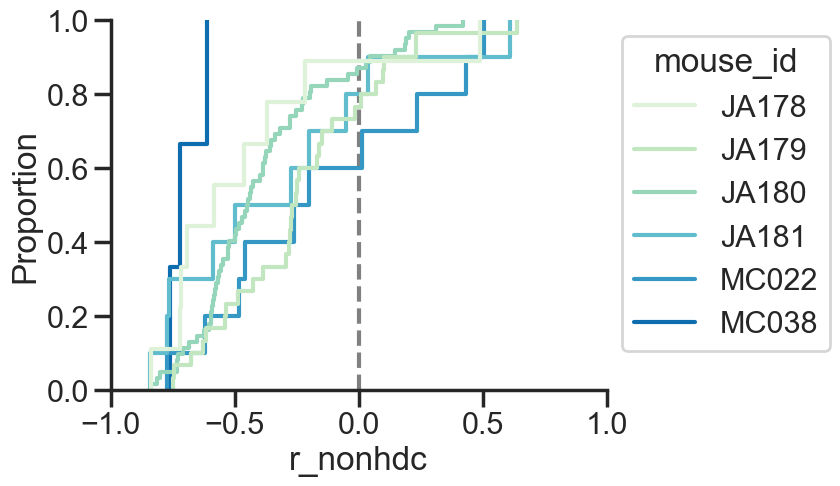

In [38]:

_inp_plot = df_mandyn.groupby(['implant', 'rec_id', 'ep_idx']).max().reset_index()
plt.axvline(x = 0, color = 'gray', ls = '--')

# y = 'r_hdc'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "mouse_id", palette = 'Reds')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

y = 'r_nonhdc'
g = sns.ecdfplot(data = _inp_plot, x = y, hue = "mouse_id", palette = 'GnBu')
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

# y = 'r_rand'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "implant", palette = 'Greys')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xlim(-1, 1)

# filepath = save_dir / f'ecdf_мr_isomap-dyn_nonhdc.pdf'
# plt.savefig(filepath, transparent = True)

(-1.0, 1.0)

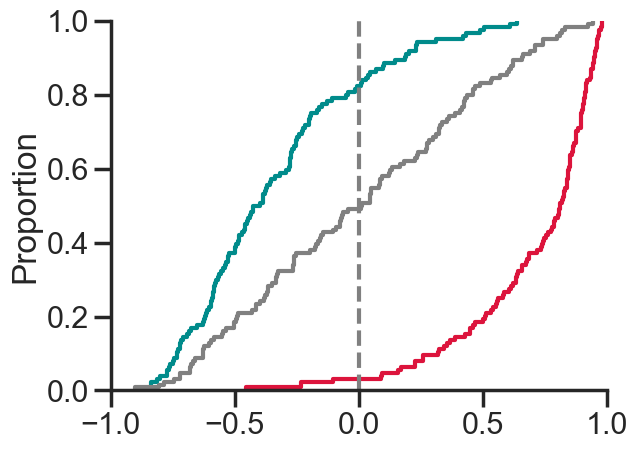

In [39]:
_inp_plot = df_mandyn[df_mandyn.offman_ep_flag == True].groupby(['implant', 
                                                                 'rec_id', 'ep_idx']).max().reset_index()

a1 = _inp_plot['r_hdc'].values
b1 = _inp_plot['r_nonhdc'].values
c1 = _inp_plot['r_rand'].values

sns.ecdfplot(a1, color = 'crimson')
sns.ecdfplot(b1, color = 'darkcyan')
sns.ecdfplot(c1, color = 'Gray')
plt.axvline(x = 0, color = 'gray', ls = '--')
plt.xlim(-1, 1)

# filepath = save_dir / f'ecdf_мr_isomap-dyn_all.pdf'
# plt.savefig(filepath, transparent = True)

In [40]:
_inp_plot.describe()

,ep_idx,r_hdc,r_nonhdc,r_rand,min_rad
count,124.000000,124.000000,124.000000,124.000000,124.000000
mean,46.145161,0.700074,-0.340803,0.003735,0.231476
std,33.371205,0.283623,0.341073,0.473146,0.196999
min,0.000000,-0.454547,-0.841424,-0.902828,0.001399
25%,23.000000,0.576316,-0.588172,-0.378227,0.046875
50%,39.500000,0.811116,-0.411531,0.009942,0.206677
75%,55.000000,0.898871,-0.187380,0.394164,0.367468
max,147.000000,0.980452,0.640710,0.944611,0.666710


In [41]:
print('r hdc vs nonhdc')
print(stats.ks_2samp(a1, b1))
print('r hdc vs rand')
print(stats.ks_2samp(a1, c1))
print('r rand vs nonhdc')
print(stats.ks_2samp(b1, c1))

r hdc vs nonhdc
KstestResult(statistic=0.8629032258064516, pvalue=7.117025776796575e-48, statistic_location=0.23580431781098937, statistic_sign=-1)
r hdc vs rand
KstestResult(statistic=0.6451612903225806, pvalue=1.287063770969988e-24, statistic_location=0.46921754328146503, statistic_sign=-1)
r rand vs nonhdc
KstestResult(statistic=0.3709677419354839, pvalue=5.520380921043013e-08, statistic_location=-0.1936991629825357, statistic_sign=1)


In [44]:
# _inp_plot.to_excel(filepath, index=True)